In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

## 读取变量

In [1]:
import numpy as np
import pandas as pd

In [2]:
#读取数据
data_raw = pd.read_excel('LR_practice.xlsx')
data_raw.head()

,id,Acc,avg_exp,gender,Age,Income,Ownrent,Selfempl,dist_home_val,dist_avg_income,edad2,edu_class
0,19,1,1217.03,Male,40,16.03515,1,1,99.93,15.932789,1600,研究生
1,5,1,1251.50,Male,32,15.84750,1,0,49.88,15.796316,1024,大学
2,86,1,856.57,Male,41,11.47285,1,0,16.10,11.275632,1681,研究生
3,50,1,1321.83,Male,28,13.40915,1,0,100.39,13.346474,784,大学
4,67,1,816.03,Male,41,10.03015,0,1,119.76,10.332263,1681,研究生


In [3]:
data_raw.tail()

,id,Acc,avg_exp,gender,Age,Income,Ownrent,Selfempl,dist_home_val,dist_avg_income,edad2,edu_class
71,53,1,491.04,Female,21,4.05520,0,0,36.81,4.349158,441,中学
72,83,1,468.61,Female,20,3.89305,0,0,66.75,4.551105,400,中学
73,43,1,593.92,Female,30,4.37960,0,0,124.23,5.040632,900,中学
74,60,1,418.78,Female,21,3.49390,0,0,34.46,3.828842,441,中学
75,28,1,163.18,Female,22,3.81590,0,0,63.27,3.997789,484,小学及以下


In [4]:
data_raw.head(2)

,id,Acc,avg_exp,gender,Age,Income,Ownrent,Selfempl,dist_home_val,dist_avg_income,edad2,edu_class
0,19,1,1217.03,Male,40,16.03515,1,1,99.93,15.932789,1600,研究生
1,5,1,1251.50,Male,32,15.84750,1,0,49.88,15.796316,1024,大学


In [5]:
#数据基本信息
data_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76 entries, 0 to 75
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               76 non-null     int64  
 1   Acc              76 non-null     int64  
 2   avg_exp          70 non-null     float64
 3   gender           76 non-null     object 
 4   Age              76 non-null     int64  
 5   Income           76 non-null     float64
 6   Ownrent          76 non-null     int64  
 7   Selfempl         76 non-null     int64  
 8   dist_home_val    76 non-null     float64
 9   dist_avg_income  76 non-null     float64
 10  edad2            76 non-null     int64  
 11  edu_class        75 non-null     object 
dtypes: float64(4), int64(6), object(2)
memory usage: 7.2+ KB


## 数据清洗

### 删除无用变量

In [6]:
#变量'id','Acc','edad2'
data_raw.drop(['id','Acc','edad2'], axis=1, inplace=True)

In [7]:
data_raw.head(2)

,avg_exp,gender,Age,Income,Ownrent,Selfempl,dist_home_val,dist_avg_income,edu_class
0,1217.03,Male,40,16.03515,1,1,99.93,15.932789,研究生
1,1251.50,Male,32,15.84750,1,0,49.88,15.796316,大学


### 重复值

In [8]:
#删除重复值
data_raw.drop_duplicates(inplace=True)

### 缺失值

In [9]:
#查看缺失情况
data_raw.isnull().mean()

avg_exp            0.078947
gender             0.000000
Age                0.000000
Income             0.000000
Ownrent            0.000000
Selfempl           0.000000
dist_home_val      0.000000
dist_avg_income    0.000000
edu_class          0.013158
dtype: float64

In [10]:
data_raw.isnull().sum()

avg_exp            6
gender             0
Age                0
Income             0
Ownrent            0
Selfempl           0
dist_home_val      0
dist_avg_income    0
edu_class          1
dtype: int64

#### 填补缺失值

In [26]:
data_raw['avg_exp'].mean()

983.6554285714292

In [27]:
#avg_exp
data_raw['avg_exp'] = data_raw['avg_exp'].fillna(data_raw['avg_exp'].mean())

In [28]:
data_raw.isnull().mean()

avg_exp            0.000000
gender             0.000000
Age                0.000000
Income             0.000000
Ownrent            0.000000
Selfempl           0.000000
dist_home_val      0.000000
dist_avg_income    0.000000
edu_class          0.013158
dtype: float64

#### 数据编码和缺失值

In [29]:
#方法1：gender
data_raw['gender'] = data_raw['gender'].map({'Male':1, 'Female':0})

In [30]:
data_raw.head(2)

,avg_exp,gender,Age,Income,Ownrent,Selfempl,dist_home_val,dist_avg_income,edu_class
0,1217.03,1,40.0,16.03515,1,1,99.93,15.932789,研究生
1,1251.50,1,32.0,15.84750,1,0,49.88,15.796316,大学


In [31]:
#方法2：edu_class
data_raw['edu_class'].unique()

array(['研究生', '大学', '中学', '小学及以下', nan], dtype=object)

In [32]:
label = data_raw['edu_class'].unique().tolist()
label

['研究生', '大学', '中学', '小学及以下', nan]

In [33]:
label.index('中学')

2

In [34]:
#对原数据进行编码
data_raw['edu_class'] = data_raw['edu_class'].apply(lambda x: label.index(x))

In [35]:
data_raw.head()

,avg_exp,gender,Age,Income,Ownrent,Selfempl,dist_home_val,dist_avg_income,edu_class
0,1217.03,1,40.0,16.03515,1,1,99.93,15.932789,0
1,1251.50,1,32.0,15.84750,1,0,49.88,15.796316,1
2,856.57,1,41.0,11.47285,1,0,16.10,11.275632,0
3,1321.83,1,28.0,13.40915,1,0,100.39,13.346474,1
4,816.03,1,41.0,10.03015,0,1,119.76,10.332263,0


In [36]:
data_raw['edu_class'].value_counts()

2    25
1    23
0    22
3     5
4     1
Name: edu_class, dtype: int64

### 异常值

#### 箱线图

In [37]:
import seaborn as sns

<AxesSubplot:>

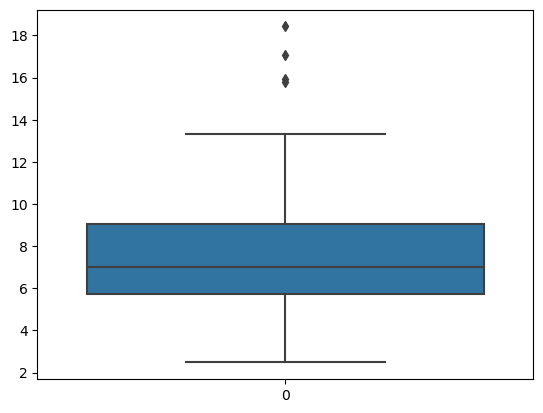

In [38]:
# dist_avg_income
sns.boxplot(data=data_raw['dist_avg_income'])

#### 3倍标准差

In [39]:
from scipy import stats

In [40]:
#标准化数据(Age)
z = stats.zscore(data_raw['Age'])
z

0     1.262619
1     0.113042
2     1.406316
3    -0.461747
4     1.406316
        ...   
71   -1.467627
72   -1.611324
73   -0.174353
74   -1.467627
75   -1.323930
Name: Age, Length: 76, dtype: float64

In [41]:
(z>3)|(z<-3)

0     False
1     False
2     False
3     False
4     False
      ...  
71    False
72    False
73    False
74    False
75    False
Name: Age, Length: 76, dtype: bool

In [42]:
#寻找异常数据的索引
z[(z>3)|(z<-3)]

45    3.418077
Name: Age, dtype: float64

In [43]:
#查看异常数据的值
data_raw['Age'].iloc[40]

31.213333333333335

如何填补999这个异常的年龄数据呢？

In [44]:
data_raw['Age'].mean()

31.21333333333333

In [45]:
data_raw['Age'].drop(index=40).mean()

31.213333333333335

In [48]:
#将异常值使用除异常值之外的数据的均值进行填补
# 1. 先计算出除了第40行之外的平均年龄
mean_age = data_raw['Age'].drop(index=40).mean()

# 2. 直接精准定位并填入
data_raw.loc[40, 'Age'] = mean_age

### 哑变量转换

In [49]:
data_raw.head()

,avg_exp,gender,Age,Income,Ownrent,Selfempl,dist_home_val,dist_avg_income,edu_class
0,1217.03,1,40.0,16.03515,1,1,99.93,15.932789,0
1,1251.50,1,32.0,15.84750,1,0,49.88,15.796316,1
2,856.57,1,41.0,11.47285,1,0,16.10,11.275632,0
3,1321.83,1,28.0,13.40915,1,0,100.39,13.346474,1
4,816.03,1,41.0,10.03015,0,1,119.76,10.332263,0


In [50]:
#edu_class
dummy = pd.get_dummies(data=data_raw['edu_class'], prefix='edu', drop_first=True)
dummy

,edu_1,edu_2,edu_3,edu_4
0,0,0,0,0
1,1,0,0,0
2,0,0,0,0
3,1,0,0,0
4,0,0,0,0
...,...,...,...,...
71,0,1,0,0
72,0,1,0,0
73,0,1,0,0
74,0,1,0,0


In [51]:
#合并到原数据
data = pd.concat([data_raw, dummy], axis=1)
data.head()

,avg_exp,gender,Age,Income,Ownrent,Selfempl,dist_home_val,dist_avg_income,edu_class,edu_1,edu_2,edu_3,edu_4
0,1217.03,1,40.0,16.03515,1,1,99.93,15.932789,0,0,0,0,0
1,1251.50,1,32.0,15.84750,1,0,49.88,15.796316,1,1,0,0,0
2,856.57,1,41.0,11.47285,1,0,16.10,11.275632,0,0,0,0,0
3,1321.83,1,28.0,13.40915,1,0,100.39,13.346474,1,1,0,0,0
4,816.03,1,41.0,10.03015,0,1,119.76,10.332263,0,0,0,0,0


## 相关分析

### 相关系数

In [52]:
data.corr()

,avg_exp,gender,Age,Income,Ownrent,Selfempl,dist_home_val,dist_avg_income,edu_class,edu_1,edu_2,edu_3,edu_4
avg_exp,1.000000e+00,0.203600,2.550378e-01,0.618998,0.296467,0.007544,0.299324,0.639808,-0.652473,-0.016009,-0.517608,-0.193775,-3.521141e-17
gender,2.035997e-01,1.000000,3.337694e-01,0.719685,0.430469,0.046657,0.190720,0.705310,-0.373224,0.126663,-0.291216,-0.158590,-6.900656e-02
Age,2.550378e-01,0.333769,1.000000e+00,0.320587,0.435519,0.097696,0.095233,0.310345,-0.305149,-0.020194,-0.258898,-0.061522,-4.190919e-17
Income,6.189981e-01,0.719685,3.205873e-01,1.000000,0.532525,-0.073450,0.271646,0.990413,-0.626842,0.033885,-0.356766,-0.300040,-1.535058e-01
Ownrent,2.964665e-01,0.430469,4.355194e-01,0.532525,1.000000,-0.115370,0.059849,0.512273,-0.328597,0.049609,-0.168620,-0.196988,-8.571429e-02
Selfempl,7.544430e-03,0.046657,9.769642e-02,-0.073450,-0.115370,1.000000,0.052527,-0.119567,0.236433,-0.192865,-0.101123,0.315952,3.944053e-01
dist_home_val,2.993244e-01,0.190720,9.523328e-02,0.271646,0.059849,0.052527,1.000000,0.286791,-0.311106,0.226996,-0.307158,-0.249559,1.443979e-01
dist_avg_income,6.398076e-01,0.705310,3.103451e-01,0.990413,0.512273,-0.119567,0.286791,1.000000,-0.648087,0.055505,-0.350248,-0.332764,-1.809021e-01
edu_class,-6.524726e-01,-0.373224,-3.051493e-01,-0.626842,-0.328597,0.236433,-0.311106,-0.648087,1.000000,-0.141865,0.565414,0.485764,3.294850e-01
edu_1,-1.600887e-02,0.126663,-2.019449e-02,0.033885,0.049609,-0.192865,0.226996,0.055505,-0.141865,1.000000,-0.461223,-0.174816,-7.606684e-02


In [53]:
#分类变量
data.corr(method='kendall')

,avg_exp,gender,Age,Income,Ownrent,Selfempl,dist_home_val,dist_avg_income,edu_class,edu_1,edu_2,edu_3,edu_4
avg_exp,1.000000,0.167236,0.230203,0.421110,0.290705,0.064150,0.160775,0.439403,-0.561243,0.072620,-0.510726,-0.111642,0.026024
gender,0.167236,1.000000,0.302455,0.558598,0.430469,0.046657,0.127615,0.556359,-0.351901,0.126663,-0.291216,-0.158590,-0.069007
Age,0.230203,0.302455,1.000000,0.289227,0.355849,0.098595,0.029280,0.278515,-0.245094,-0.062241,-0.208202,-0.042492,0.019810
Income,0.421110,0.558598,0.289227,1.000000,0.474305,-0.135274,0.153684,0.909474,-0.551915,0.026289,-0.302690,-0.297259,-0.149244
Ownrent,0.290705,0.430469,0.355849,0.474305,1.000000,-0.115370,0.035534,0.462975,-0.300133,0.049609,-0.168620,-0.196988,-0.085714
Selfempl,0.064150,0.046657,0.098595,-0.135274,-0.115370,1.000000,0.038389,-0.148070,0.154962,-0.192865,-0.101123,0.315952,0.394405
dist_home_val,0.160775,0.127615,0.029280,0.153684,0.035534,0.038389,1.000000,0.151579,-0.263564,0.192606,-0.260723,-0.193864,0.118962
dist_avg_income,0.439403,0.556359,0.278515,0.909474,0.462975,-0.148070,0.151579,1.000000,-0.573397,0.064917,-0.315280,-0.315154,-0.157896
edu_class,-0.561243,-0.351901,-0.245094,-0.551915,-0.300133,0.154962,-0.263564,-0.573397,1.000000,-0.130755,0.602196,0.403825,0.190994
edu_1,0.072620,0.126663,-0.062241,0.026289,0.049609,-0.192865,0.192606,0.064917,-0.130755,1.000000,-0.461223,-0.174816,-0.076067


### 散点图

In [54]:
import matplotlib.pyplot as plt

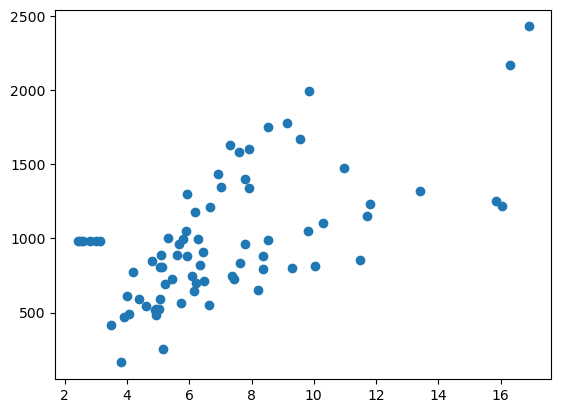

In [55]:
# avg_exp和Income
plt.scatter(data['Income'], data['avg_exp'])

## 回归分析

### 回归模型

In [56]:
from statsmodels.formula.api import ols

In [57]:
data.columns

Index(['avg_exp', 'gender', 'Age', 'Income', 'Ownrent', 'Selfempl',
       'dist_home_val', 'dist_avg_income', 'edu_class', 'edu_1', 'edu_2',
       'edu_3', 'edu_4'],
      dtype='object')

In [58]:
data.head()

,avg_exp,gender,Age,Income,Ownrent,Selfempl,dist_home_val,dist_avg_income,edu_class,edu_1,edu_2,edu_3,edu_4
0,1217.03,1,40.0,16.03515,1,1,99.93,15.932789,0,0,0,0,0
1,1251.50,1,32.0,15.84750,1,0,49.88,15.796316,1,1,0,0,0
2,856.57,1,41.0,11.47285,1,0,16.10,11.275632,0,0,0,0,0
3,1321.83,1,28.0,13.40915,1,0,100.39,13.346474,1,1,0,0,0
4,816.03,1,41.0,10.03015,0,1,119.76,10.332263,0,0,0,0,0


In [59]:
# model_1 = ols(LR1, data)
# model_1 = model_1.fit()

In [60]:
LR1 = 'avg_exp~gender+Age+ Income+ Ownrent+ Selfempl+dist_home_val+ dist_avg_income+edu_1+ edu_2+edu_3+ edu_4'
model_1 = ols(LR1, data).fit()

In [61]:
model_1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                avg_exp   R-squared:                       0.720
Model:                            OLS   Adj. R-squared:                  0.671
Method:                 Least Squares   F-statistic:                     14.93
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           8.36e-14
Time:                        10:09:32   Log-Likelihood:                -519.52
No. Observations:                  76   AIC:                             1063.
Df Residuals:                      64   BIC:                             1091.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept         535.9565    223.038      2.403      0.019      90.387     981.526
gender           -447.4828     97.100     -4.608      0.000    -641.463    -253.503
Age                 0.6121      4.779      0.128      0.898      -8.936      10.160
Income           -119.1929     72.411     -1.646      0.105    -263.850      25.464
Ownrent            41.3184     76.416      0.541      0.591    -111.341     193.977
Selfempl          153.7000    129.424      1.188      0.239    -104.853     412.253
dist_home_val       0.1579      0.859      0.184      0.855      -1.557       1.873
dist_avg_income   211.5250     71.122      2.974      0.004      69.442     353.608
edu_1            -262.5083     82.890     -3.167      0.002    -428.100     -96.916
edu_2            -495.1400     92.266     -5.366      0.000    -679.462    -310.818
edu_3            -292.5211    156.617     -1.868      0.066    -605.400      20.358
edu_4              49.3783    294.618      0.168      0.867    -539.188     637.945
==============================================================================
Omnibus:                        0.894   Durbin-Watson:                   2.112
Prob(Omnibus):                  0.640   Jarque-Bera (JB):                0.613
Skew:                          -0.219   Prob(JB):                        0.736
Kurtosis:                       3.044   Cond. No.                     1.00e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large,  1e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [62]:
#常用接口
dir(model_1)

['HC0_se',
 'HC1_se',
 'HC2_se',
 'HC3_se',
 '_HCCM',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_abat_diagonal',
 '_cache',
 '_data_attr',
 '_data_in_cache',
 '_get_robustcov_results',
 '_is_nested',
 '_use_t',
 '_wexog_singular_values',
 'aic',
 'bic',
 'bse',
 'centered_tss',
 'compare_f_test',
 'compare_lm_test',
 'compare_lr_test',
 'condition_number',
 'conf_int',
 'conf_int_el',
 'cov_HC0',
 'cov_HC1',
 'cov_HC2',
 'cov_HC3',
 'cov_kwds',
 'cov_params',
 'cov_type',
 'df_model',
 'df_resid',
 'diagn',
 'eigenvals',
 'el_test',
 'ess',
 'f_pvalue',
 'f_test',
 'fittedvalues',
 'fvalue',
 'get_influence',
 'get_prediction',
 'get_robustcov_results',
 'info_c

In [63]:
model_1.resid

0    -565.630770
1     -95.652529
2    -318.456003
3     196.720056
4    -460.157387
         ...    
71     -5.047028
72    -93.635981
73    -29.075904
74    -33.779180
75   -494.515263
Length: 76, dtype: float64

### 模型调优

#### 共线性

In [48]:
data.head()

,avg_exp,gender,Age,Income,Ownrent,Selfempl,dist_home_val,dist_avg_income,edu_class,edu_1,edu_2,edu_3,edu_4
0,1217.03,1,40.0,16.03515,1,1,99.93,15.932789,0,False,False,False,False
1,1251.50,1,32.0,15.84750,1,0,49.88,15.796316,1,True,False,False,False
2,856.57,1,41.0,11.47285,1,0,16.10,11.275632,0,False,False,False,False
3,1321.83,1,28.0,13.40915,1,0,100.39,13.346474,1,True,False,False,False
4,816.03,1,41.0,10.03015,0,1,119.76,10.332263,0,False,False,False,False


In [49]:
def vif(df, y_col):
    x_cols = list(df.columns)
    x_cols.remove(y_col)
    formula = y_col + '~' + '+'.join(x_cols)
    rsquared = ols(formula, df).fit().rsquared
    return 1. / (1. - rsquared)

exog = data[['gender','Age','Income','Ownrent','Selfempl','dist_home_val','dist_avg_income','edu_class']]

for y_col in exog.columns:
    print(y_col, '\t', vif(df=exog, y_col=y_col))

gender 	 2.209191974683995
Age 	 1.3708810657506336
Income 	 64.76239230667133
Ownrent 	 1.668281771649641
Selfempl 	 1.2887640187408764
dist_home_val 	 1.1654312430431526
dist_avg_income 	 64.13992249399934
edu_class 	 1.994586770890881


In [50]:
#重新拟合模型
LR2 = 'avg_exp~gender+Age+ Income+ Ownrent+ Selfempl+dist_home_val+edu_1+ edu_2+edu_3+ edu_4'
model_2 = ols(LR2, data).fit()
model_2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                avg_exp   R-squared:                       0.681
Model:                            OLS   Adj. R-squared:                  0.632
Method:                 Least Squares   F-statistic:                     13.87
Date:                Sun, 04 May 2025   Prob (F-statistic):           1.07e-12
Time:                        18:15:59   Log-Likelihood:                -524.44
No. Observations:                  76   AIC:                             1071.
Df Residuals:                      65   BIC:                             1097.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept       659.2949    231.997      2.842      0.006     195.965    1122.625
edu_1[T.True]  -258.0157     87.735     -2.941      0.005    -433.235     -82.796
edu_2[T.True]  -507.3032     97.579     -5.199      0.000    -702.182    -312.424
edu_3[T.True]  -377.0725    163.045     -2.313      0.024    -702.696     -51.449
edu_4[T.True]   -89.4791    307.950     -0.291      0.772    -704.497     525.539
gender         -451.7062    102.782     -4.395      0.000    -656.976    -246.436
Age               1.1647      5.056      0.230      0.819      -8.932      11.262
Income           90.5062     17.456      5.185      0.000      55.644     125.369
Ownrent           3.8211     79.788      0.048      0.962    -155.526     163.168
Selfempl         69.9220    133.727      0.523      0.603    -197.149     336.993
dist_home_val     0.4438      0.903      0.491      0.625      -1.360       2.248
==============================================================================
Omnibus:                        1.477   Durbin-Watson:                   1.892
Prob(Omnibus):                  0.478   Jarque-Bera (JB):                0.850
Skew:                           0.153   Prob(JB):                        0.654
Kurtosis:                       3.418   Cond. No.                         979.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

#### 同方差

残差图：   
- 一元回归：横坐标是X，纵坐标是残差
- 多元回归：横坐标是Y的拟合值，纵坐标是残差

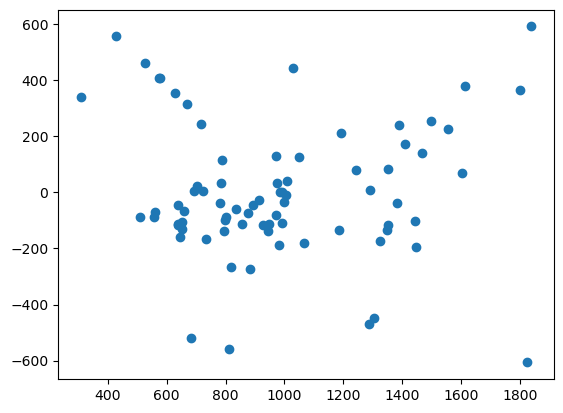

In [51]:
#残差图
plt.scatter(model_2.predict(data), model_2.resid)

#### 正态性

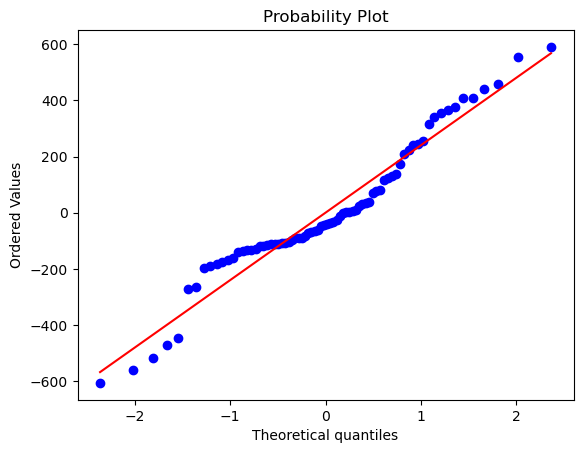

In [52]:
res = stats.probplot(model_2.resid, plot=plt)

In [53]:
data['ln_avg_exp'] = np.log(data['avg_exp'])
data.head()

,avg_exp,gender,Age,Income,Ownrent,Selfempl,dist_home_val,dist_avg_income,edu_class,edu_1,edu_2,edu_3,edu_4,ln_avg_exp
0,1217.03,1,40.0,16.03515,1,1,99.93,15.932789,0,False,False,False,False,7.104169
1,1251.50,1,32.0,15.84750,1,0,49.88,15.796316,1,True,False,False,False,7.132098
2,856.57,1,41.0,11.47285,1,0,16.10,11.275632,0,False,False,False,False,6.752936
3,1321.83,1,28.0,13.40915,1,0,100.39,13.346474,1,True,False,False,False,7.186772
4,816.03,1,41.0,10.03015,0,1,119.76,10.332263,0,False,False,False,False,6.704451


In [54]:
#重新拟合模型
LR3 = 'ln_avg_exp~gender+Age+ Income+ Ownrent+ Selfempl+dist_home_val+edu_1+ edu_2+edu_3+ edu_4'
model_3 = ols(LR3, data).fit()
model_3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             ln_avg_exp   R-squared:                       0.614
Model:                            OLS   Adj. R-squared:                  0.554
Method:                 Least Squares   F-statistic:                     10.33
Date:                Sun, 04 May 2025   Prob (F-statistic):           3.57e-10
Time:                        18:16:04   Log-Likelihood:                -11.749
No. Observations:                  76   AIC:                             45.50
Df Residuals:                      65   BIC:                             71.14
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         6.6463      0.273     24.368      0.000       6.102       7.191
edu_1[T.True]    -0.1870      0.103     -1.813      0.074      -0.393       0.019
edu_2[T.True]    -0.5625      0.115     -4.903      0.000      -0.792      -0.333
edu_3[T.True]    -0.7905      0.192     -4.124      0.000      -1.173      -0.408
edu_4[T.True]    -0.2752      0.362     -0.760      0.450      -0.998       0.448
gender           -0.3841      0.121     -3.179      0.002      -0.625      -0.143
Age               0.0023      0.006      0.392      0.696      -0.010       0.014
Income            0.0649      0.021      3.162      0.002       0.024       0.106
Ownrent           0.0743      0.094      0.792      0.431      -0.113       0.262
Selfempl          0.3216      0.157      2.046      0.045       0.008       0.636
dist_home_val    -0.0005      0.001     -0.444      0.658      -0.003       0.002
==============================================================================
Omnibus:                       10.941   Durbin-Watson:                   1.800
Prob(Omnibus):                  0.004   Jarque-Bera (JB):               18.504
Skew:                          -0.485   Prob(JB):                     9.59e-05
Kurtosis:                       5.214   Cond. No.                         979.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

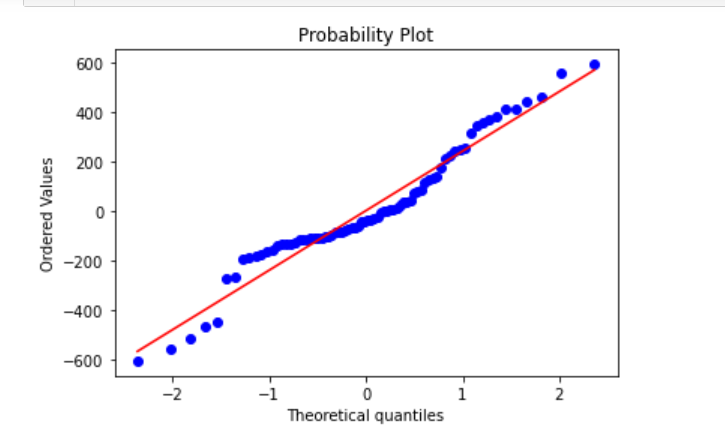

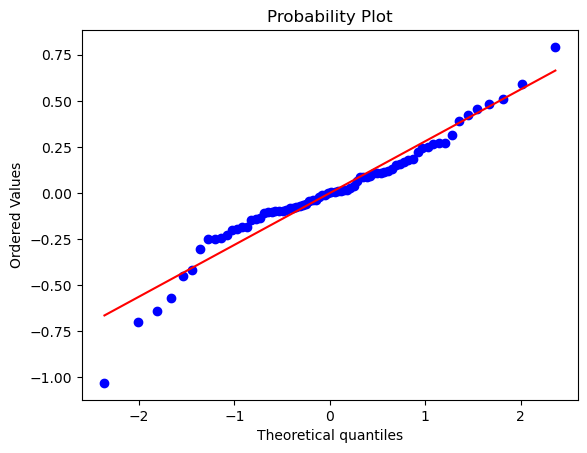

In [55]:
res = stats.probplot(model_3.resid, plot=plt)

#### 高次项

In [56]:
data['Age_sq'] = data['Age']**2
data.head()

,avg_exp,gender,Age,Income,Ownrent,Selfempl,dist_home_val,dist_avg_income,edu_class,edu_1,edu_2,edu_3,edu_4,ln_avg_exp,Age_sq
0,1217.03,1,40.0,16.03515,1,1,99.93,15.932789,0,False,False,False,False,7.104169,1600.0
1,1251.50,1,32.0,15.84750,1,0,49.88,15.796316,1,True,False,False,False,7.132098,1024.0
2,856.57,1,41.0,11.47285,1,0,16.10,11.275632,0,False,False,False,False,6.752936,1681.0
3,1321.83,1,28.0,13.40915,1,0,100.39,13.346474,1,True,False,False,False,7.186772,784.0
4,816.03,1,41.0,10.03015,0,1,119.76,10.332263,0,False,False,False,False,6.704451,1681.0


In [57]:
#年龄
LR4 = 'ln_avg_exp~gender+Age+ Income+ Ownrent+ Selfempl+dist_home_val+edu_1+ edu_2+edu_3+ edu_4 + Age_sq'
model_4 = ols(LR4, data).fit()
model_4.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             ln_avg_exp   R-squared:                       0.689
Model:                            OLS   Adj. R-squared:                  0.636
Method:                 Least Squares   F-statistic:                     12.89
Date:                Sun, 04 May 2025   Prob (F-statistic):           1.90e-12
Time:                        18:16:08   Log-Likelihood:                -3.5070
No. Observations:                  76   AIC:                             31.01
Df Residuals:                      64   BIC:                             58.98
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         4.4947      0.600      7.496      0.000       3.297       5.692
edu_1[T.True]    -0.1415      0.094     -1.505      0.137      -0.329       0.046
edu_2[T.True]    -0.5674      0.104     -5.469      0.000      -0.775      -0.360
edu_3[T.True]    -0.8177      0.173     -4.714      0.000      -1.164      -0.471
edu_4[T.True]    -0.4300      0.330     -1.304      0.197      -1.089       0.229
gender           -0.3972      0.109     -3.634      0.001      -0.616      -0.179
Age               0.1400      0.035      3.957      0.000       0.069       0.211
Income            0.0485      0.019      2.551      0.013       0.011       0.087
Ownrent           0.1197      0.086      1.398      0.167      -0.051       0.291
Selfempl          0.3098      0.142      2.179      0.033       0.026       0.594
dist_home_val -7.356e-05      0.001     -0.076      0.940      -0.002       0.002
Age_sq           -0.0020      0.001     -3.937      0.000      -0.003      -0.001
==============================================================================
Omnibus:                        8.638   Durbin-Watson:                   1.582
Prob(Omnibus):                  0.013   Jarque-Bera (JB):               14.313
Skew:                          -0.339   Prob(JB):                     0.000780
Kurtosis:                       5.015   Cond. No.                     2.15e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.15e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

#### 交互项

In [58]:
data['Age_gender'] = data['Age']*data['gender']
data.head()

,avg_exp,gender,Age,Income,Ownrent,Selfempl,dist_home_val,dist_avg_income,edu_class,edu_1,edu_2,edu_3,edu_4,ln_avg_exp,Age_sq,Age_gender
0,1217.03,1,40.0,16.03515,1,1,99.93,15.932789,0,False,False,False,False,7.104169,1600.0,40.0
1,1251.50,1,32.0,15.84750,1,0,49.88,15.796316,1,True,False,False,False,7.132098,1024.0,32.0
2,856.57,1,41.0,11.47285,1,0,16.10,11.275632,0,False,False,False,False,6.752936,1681.0,41.0
3,1321.83,1,28.0,13.40915,1,0,100.39,13.346474,1,True,False,False,False,7.186772,784.0,28.0
4,816.03,1,41.0,10.03015,0,1,119.76,10.332263,0,False,False,False,False,6.704451,1681.0,41.0


In [59]:
LR5 = 'ln_avg_exp~gender+Age+ Income+ Ownrent+ Selfempl+dist_home_val+edu_1+ edu_2+edu_3+ edu_4 + Age_sq+Age_gender'
model_5 = ols(LR5, data).fit()
model_5.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             ln_avg_exp   R-squared:                       0.713
Model:                            OLS   Adj. R-squared:                  0.658
Method:                 Least Squares   F-statistic:                     13.03
Date:                Sun, 04 May 2025   Prob (F-statistic):           6.86e-13
Time:                        18:16:10   Log-Likelihood:               -0.50019
No. Observations:                  76   AIC:                             27.00
Df Residuals:                      63   BIC:                             57.30
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         4.5002      0.581      7.747      0.000       3.339       5.661
edu_1[T.True]    -0.1374      0.091     -1.509      0.136      -0.319       0.045
edu_2[T.True]    -0.5555      0.101     -5.520      0.000      -0.757      -0.354
edu_3[T.True]    -0.8230      0.168     -4.897      0.000      -1.159      -0.487
edu_4[T.True]    -0.4744      0.320     -1.482      0.143      -1.114       0.165
gender            0.5339      0.422      1.264      0.211      -0.310       1.378
Age               0.1331      0.034      3.867      0.000       0.064       0.202
Income            0.0518      0.018      2.802      0.007       0.015       0.089
Ownrent           0.1088      0.083      1.309      0.195      -0.057       0.275
Selfempl          0.3698      0.140      2.637      0.011       0.090       0.650
dist_home_val -1.754e-05      0.001     -0.019      0.985      -0.002       0.002
Age_sq           -0.0018      0.001     -3.647      0.001      -0.003      -0.001
Age_gender       -0.0276      0.012     -2.278      0.026      -0.052      -0.003
==============================================================================
Omnibus:                        7.398   Durbin-Watson:                   1.573
Prob(Omnibus):                  0.025   Jarque-Bera (JB):               12.777
Skew:                          -0.194   Prob(JB):                      0.00168
Kurtosis:                       4.971   Cond. No.                     2.15e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.15e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""